# Thyroid Disease Classification

Predict whether a patient is hypothyroid from four blood tests plus age and sex, using a
random forest.

The only label column is `binaryClass`, which has two values, so this is a binary problem.
The positive class is small, so accuracy is not used below — recall and precision for the
hypothyroid class are.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.preprocessing import LabelEncoder

CSV = "../dataset/hypothyroid.csv"
FEATURES = ["age", "sex", "TSH", "TT4", "T4U", "FTI"]
LABS = ["TSH", "TT4", "T4U", "FTI"]
TARGET = "binaryClass"
CLASS_NAMES = ["negative", "hypothyroid"]
RANDOM_STATE = 42

## 2. Load the raw data

The file marks a missing entry with a question mark, so `na_values="?"` is needed for pandas
to read those as missing instead of as text.

In [2]:
df = pd.read_csv(CSV, na_values="?")
print(f"shape: {df.shape}")
df.head()

shape: (3772, 30)


,age,sex,on thyroxine,query on thyroxine,on antithyroid medication,sick,pregnant,thyroid surgery,I131 treatment,query hypothyroid,...,TT4 measured,TT4,T4U measured,T4U,FTI measured,FTI,TBG measured,TBG,referral source,binaryClass
0,41.0,F,f,f,f,f,f,f,f,f,...,t,125.0,t,1.14,t,109.0,f,NaN,SVHC,P
1,23.0,F,f,f,f,f,f,f,f,f,...,t,102.0,f,NaN,f,NaN,f,NaN,other,P
2,46.0,M,f,f,f,f,f,f,f,f,...,t,109.0,t,0.91,t,120.0,f,NaN,other,P
3,70.0,F,t,f,f,f,f,f,f,f,...,t,175.0,f,NaN,f,NaN,f,NaN,other,P
4,70.0,F,f,f,f,f,f,f,f,f,...,t,61.0,t,0.87,t,70.0,f,NaN,SVI,P


## 3. Cleaning

The data cannot go into a model as it stands. This section fixes it one step at a time.

### 3.1 What needs fixing

In [3]:
print("column types:")
print(df.dtypes.value_counts().to_string())

print("\nmissing values in the columns we need:")
print(df[FEATURES + [TARGET]].isna().sum().to_string())

print(f"\nduplicate rows: {df.duplicated().sum()}")
print(f"age range: {df['age'].min():.0f} to {df['age'].max():.0f}")

column types:
object     23
float64     7

missing values in the columns we need:
age              1
sex            150
TSH            369
TT4            231
T4U            387
FTI            385
binaryClass      0

duplicate rows: 61
age range: 1 to 455


### 3.2 Keep the columns we need

The file has 30 columns. This model uses four blood tests plus age and sex, so everything else
is dropped. The clinical history flags are left out on purpose: `on thyroxine` and the rest
record that a thyroid problem was *already* diagnosed and treated, which a screening model
would not know.

In [4]:
df = df[FEATURES + [TARGET]]
print(f"shape: {df.shape}")
df.head()

shape: (3772, 7)


,age,sex,TSH,TT4,T4U,FTI,binaryClass
0,41.0,F,1.30,125.0,1.14,109.0,P
1,23.0,F,4.10,102.0,NaN,NaN,P
2,46.0,M,0.98,109.0,0.91,120.0,P
3,70.0,F,0.16,175.0,NaN,NaN,P
4,70.0,F,0.72,61.0,0.87,70.0,P


### 3.3 Encode `sex`

`sex` is stored as text. `LabelEncoder` turns the values of a column into whole numbers, but it
cannot handle missing values, so it is fitted on the rows where sex is known and the blank rows
are left blank.

In [5]:
known = df["sex"].notna()
print(f"sex is known for {known.sum()} patients and missing for {(~known).sum()}")

encoder = LabelEncoder()
df.loc[known, "sex"] = encoder.fit_transform(df.loc[known, "sex"])
df["sex"] = df["sex"].astype(float)

print(f"mapping used: {dict(zip(encoder.classes_, encoder.transform(encoder.classes_)))}")

sex is known for 3622 patients and missing for 150
mapping used: {'F': np.int64(0), 'M': np.int64(1)}


### 3.4 Encode the target

`binaryClass` is the column to predict. `LabelEncoder` numbers values alphabetically, which has
nothing to do with their meaning, so it is worth checking which group got which number.

Hypothyroidism means an underactive thyroid, so **TSH rises** and **TT4 falls**. Comparing those
two tests across the encoded classes shows which number is the hypothyroid one.

In [6]:
encoder = LabelEncoder()
df[TARGET] = encoder.fit_transform(df[TARGET])
print(f"mapping used: {dict(zip(encoder.classes_, encoder.transform(encoder.classes_)))}")

print("\nmedian result by encoded class:")
print(df.groupby(TARGET)[["TSH", "TT4"]].median().to_string())
print("\npatients per encoded class:")
print(df[TARGET].value_counts().sort_index().to_string())

mapping used: {'N': np.int64(0), 'P': np.int64(1)}

median result by encoded class:
              TSH    TT4
binaryClass             
0            12.0   76.5
1             1.2  105.0

patients per encoded class:
binaryClass
0     291
1    3481


Class `0` has the high TSH and the low TT4, so class `0` is the hypothyroid group. The
alphabetical order put it the wrong way round.

Swap the labels so that **`1` means hypothyroid**. Scikit-learn reports recall and precision for
class `1` by default, and recall only means "patients we caught" if `1` is the group being
looked for.

In [7]:
df[TARGET] = 1 - df[TARGET]

print(df.groupby(TARGET)[["TSH", "TT4"]].median().to_string())
print(f"\n0 = {CLASS_NAMES[0]}, 1 = {CLASS_NAMES[1]}")
print(df[TARGET].value_counts().sort_index().to_string())

              TSH    TT4
binaryClass             
0             1.2  105.0
1            12.0   76.5

0 = negative, 1 = hypothyroid
binaryClass
0    3481
1     291


### 3.5 Remove the impossible age

Section 3.1 showed an age beyond a human lifespan, so that row is a data entry error.

In [8]:
too_old = df["age"] > 120
print(f"{too_old.sum()} row(s) with an impossible age:")
print(df.loc[too_old].to_string())

df = df[~too_old]
print(f"\nshape: {df.shape}")

1 row(s) with an impossible age:
        age  sex  TSH    TT4   T4U    FTI  binaryClass
1364  455.0  0.0  1.1  118.0  1.13  104.0            0

shape: (3771, 7)


### 3.6 Drop duplicate rows

Identical rows have to go before the train/test split, otherwise the same patient can appear in
both and the test score stops measuring performance on unseen patients.

In [9]:
clean = df.drop_duplicates()
print(f"dropped {len(df) - len(clean)} duplicate rows -> {len(clean)} remain")

dropped 113 duplicate rows -> 3658 remain


### 3.7 The missing blood tests stay missing

A gap means the test was never ordered, not that something went wrong. Filling it with the
column average would invent a reading the patient never had, and the model could not then tell
a real result from a filled-in one. Scikit-learn's random forest accepts missing values
directly, so the gaps are left alone.

In [10]:
print("missing values remaining:")
print(clean[FEATURES].isna().sum().to_string())
print(f"\nfinal shape: {clean.shape}  ({len(FEATURES)} features + target)")
clean.head()

missing values remaining:
age      1
sex    148
TSH    257
TT4    119
T4U    275
FTI    273

final shape: (3658, 7)  (6 features + target)


,age,sex,TSH,TT4,T4U,FTI,binaryClass
0,41.0,0.0,1.30,125.0,1.14,109.0,0
1,23.0,0.0,4.10,102.0,NaN,NaN,0
2,46.0,1.0,0.98,109.0,0.91,120.0,0
3,70.0,0.0,0.16,175.0,NaN,NaN,0
4,70.0,0.0,0.72,61.0,0.87,70.0,0


## 4. Exploratory analysis

### 4.1 Class balance

In [11]:
counts = clean[TARGET].value_counts().sort_index()
pd.DataFrame({"n": counts, "pct": (100 * counts / len(clean)).round(2)}).rename(
    index={0: "negative", 1: "hypothyroid"}
)

,n,pct
binaryClass,,
negative,3367,92.04
hypothyroid,291,7.96


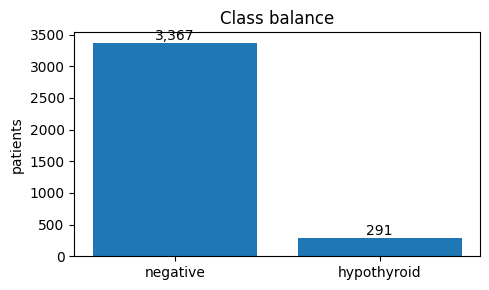

In [12]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(CLASS_NAMES, counts.values)
ax.set_ylabel("patients")
ax.set_title("Class balance")
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

### 4.2 Blood tests by class

TSH spans a very wide range, so it is drawn on a log axis. Patients whose test was not run are
left out of each panel.

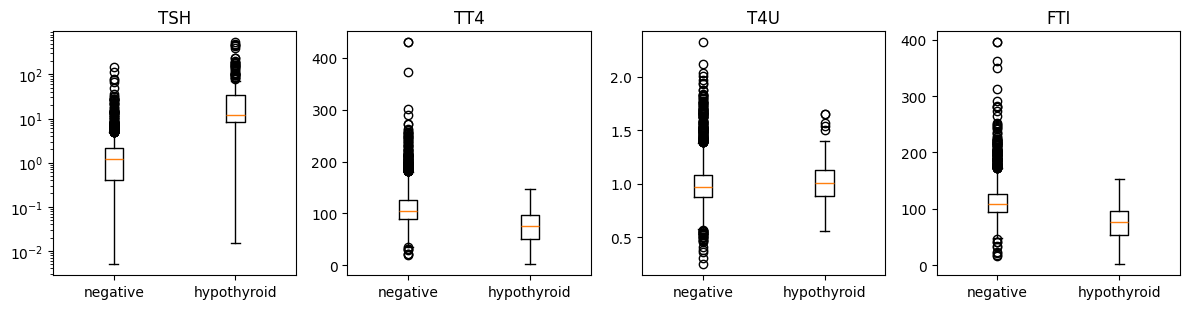

,TSH,TT4,T4U,FTI
binaryClass,,,,
negative,1.2,105.0,0.97,109.0
hypothyroid,12.0,76.5,1.01,77.5


In [13]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))

for ax, col in zip(axes, LABS):
    sub = clean[clean[col].notna()]
    data = [sub.loc[sub[TARGET] == k, col].values for k in (0, 1)]
    ax.boxplot(data, tick_labels=CLASS_NAMES)
    if col == "TSH":
        ax.set_yscale("log")
    ax.set_title(col)

plt.tight_layout()
plt.show()

clean.groupby(TARGET)[LABS].median().rename(index={0: "negative", 1: "hypothyroid"}).round(2)

## 5. Train / test split

Stratified, so both sides keep the same share of hypothyroid patients.

In [14]:
X = clean[FEATURES]
y = clean[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"train {X_train.shape}  positives {y_train.sum()}")
print(f"test  {X_test.shape}  positives {y_test.sum()}")

train (2926, 6)  positives 233
test  (732, 6)  positives 58


## 6. Random forest

`class_weight="balanced"` so the small positive class is not ignored. Cross-validation on the
training folds first, to check the model is stable before using the test set.

In [15]:
rf = RandomForestClassifier(
    n_estimators=500,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

cv = cross_validate(
    rf, X_train, y_train,
    cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
    scoring=["average_precision", "recall", "precision", "f1"],
)
pd.DataFrame({k.replace("test_", ""): v for k, v in cv.items()
              if k.startswith("test_")}).agg(["mean", "std"]).T.round(4)

,mean,std
average_precision,0.8837,0.0419
recall,0.9744,0.0461
precision,0.7899,0.0564
f1,0.8721,0.0491


In [16]:
rf.fit(X_train, y_train)
proba = rf.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print(classification_report(y_test, pred, target_names=CLASS_NAMES, digits=4))
print(f"average precision: {average_precision_score(y_test, proba):.4f}")

              precision    recall  f1-score   support

    negative     1.0000    0.9852    0.9925       674
 hypothyroid     0.8529    1.0000    0.9206        58

    accuracy                         0.9863       732
   macro avg     0.9265    0.9926    0.9566       732
weighted avg     0.9883    0.9863    0.9868       732

average precision: 0.9315


## 7. Evaluation

### 7.1 Confusion matrix

For a screening test the bottom-left cell — hypothyroid patients called negative — is the
expensive error.

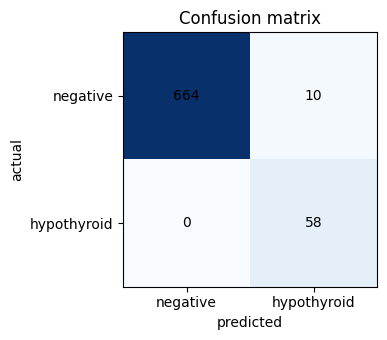

In [17]:
cm = confusion_matrix(y_test, pred)
fig, ax = plt.subplots(figsize=(4, 3.5))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center")
ax.set_xticks([0, 1], CLASS_NAMES)
ax.set_yticks([0, 1], CLASS_NAMES)
ax.set_xlabel("predicted")
ax.set_ylabel("actual")
ax.set_title("Confusion matrix")
plt.tight_layout()
plt.show()

### 7.2 Precision-recall curve

The baseline for this curve is the share of positives, not 0.5.

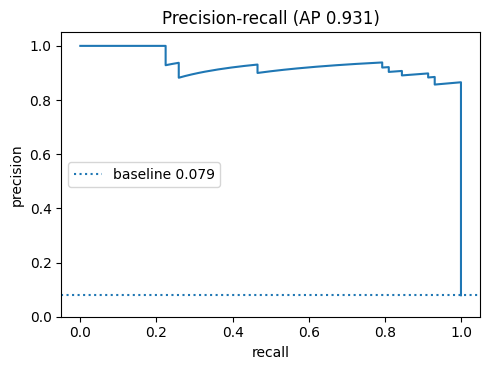

In [18]:
prec, rec, thr = precision_recall_curve(y_test, proba)

fig, ax = plt.subplots(figsize=(5, 3.8))
ax.plot(rec, prec)
ax.axhline(y_test.mean(), linestyle=":", label=f"baseline {y_test.mean():.3f}")
ax.set_xlabel("recall")
ax.set_ylabel("precision")
ax.set_title(f"Precision-recall (AP {average_precision_score(y_test, proba):.3f})")
ax.set_ylim(0, 1.05)
ax.legend()
plt.tight_layout()
plt.show()

### 7.3 Threshold choice

0.5 is an arbitrary cut. Sweeping it shows what precision costs in recall.

In [19]:
rows = []
for t in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    p = (proba >= t).astype(int)
    rows.append({
        "threshold": t,
        "recall": round(((p == 1) & (y_test == 1)).sum() / (y_test == 1).sum(), 4),
        "precision": round(((p == 1) & (y_test == 1)).sum() / max((p == 1).sum(), 1), 4),
        "missed": int(((p == 0) & (y_test == 1)).sum()),
        "false_alarms": int(((p == 1) & (y_test == 0)).sum()),
    })
pd.DataFrame(rows).set_index("threshold")

,recall,precision,missed,false_alarms
threshold,,,,
0.1,1.0000,0.7160,0,23
0.2,1.0000,0.8056,0,14
0.3,1.0000,0.8406,0,11
0.4,1.0000,0.8529,0,10
0.5,1.0000,0.8529,0,10
0.6,0.9655,0.8615,2,9
0.7,0.9483,0.8594,3,9
0.8,0.9310,0.8852,4,7


## 8. Which features matter

Permutation importance on the test set, scored by average precision.

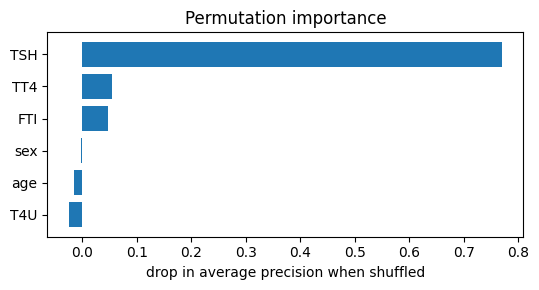

TSH    0.7692
TT4    0.0547
FTI    0.0480
sex   -0.0033
age   -0.0157
T4U   -0.0245
dtype: float64

In [20]:
pi = permutation_importance(
    rf, X_test, y_test, n_repeats=20, random_state=RANDOM_STATE,
    scoring="average_precision", n_jobs=-1,
)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(5.5, 3))
ax.barh(imp.index, imp.values)
ax.set_xlabel("drop in average precision when shuffled")
ax.set_title("Permutation importance")
plt.tight_layout()
plt.show()

imp.sort_values(ascending=False).round(4)

### Dropping features one at a time

TSH dominates the importance, so the obvious check is how much the model depends on it.

In [21]:
def score(cols):
    m = RandomForestClassifier(n_estimators=500, min_samples_leaf=2, class_weight="balanced",
                               random_state=RANDOM_STATE, n_jobs=-1)
    m.fit(X_train[cols], y_train)
    p = m.predict_proba(X_test[cols])[:, 1]
    return round(average_precision_score(y_test, p), 4)

rows = [{"features": "all 6", "avg_precision": score(FEATURES)}]
for col in FEATURES:
    rows.append({"features": f"without {col}",
                 "avg_precision": score([c for c in FEATURES if c != col])})
rows.append({"features": "TSH only", "avg_precision": score(["TSH"])})
pd.DataFrame(rows).set_index("features")

,avg_precision
features,
all 6,0.9315
without age,0.9354
without sex,0.9467
without TSH,0.4471
without TT4,0.9359
without T4U,0.9446
without FTI,0.9318
TSH only,0.8646
